# Module 7 — Graph Representation Learning

*Live session, 1.5h. Run alongside the discussion.*

Modules 3 to 5 built a graph and asked it questions. Today a model learns from
it — and the first thing to settle is whether it should.

A graph is not a table, so something has to turn a node's neighbours into a row.
A query can do that with `avg()`. A graph neural network does it with weights it
learns. Most of this session is about telling those two apart.

Today: **does the graph help, and is a graph neural network the way to use it?**


In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import torch

# The drawings live in `pictures.py`, next to this notebook: what belongs in a
# cell is which data is drawn, not the matplotlib that places a label.
from IPython.display import SVG, display
from pictures import (BLUE, FADED, ORANGE, chicago_task, club, forward_pass,
                      hops_picture, message_passing, neo4j_to_pyg,
                      owner_timelines, sides, training_loop, two_splits)

# Figures as SVG, not PNG: they stay sharp at any width, and the page these
# notebooks are published as embeds SVG and drops a PNG.
%config InlineBackend.figure_formats = ["svg"]


## Thirty-four members, and eight you know about

A karate club split in two after a quarrel between the instructor, Mr. Hi, and
the club president. Which side each of the 34 members left with was recorded,
and that recording is what makes this a dataset rather than an anecdote.

Suppose you know the side of **eight** of them. The other **26** you do not.
Fill them in.

That is a registry with holes, and it is the same shape as the problem three
sections from now, where the registry covers 193,848 business owners and the
holes are not ours to choose.


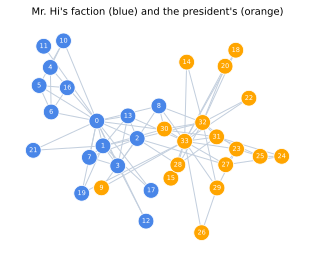

<Axes: title={'center': "Mr. Hi's faction (blue) and the president's (orange)"}>

In [2]:
G = nx.karate_club_graph()
members = list(G.nodes())
y = np.array([0 if G.nodes[n]["club"] == "Mr. Hi" else 1 for n in members])

# One layout, computed once and handed to every figure below.
pos = nx.spring_layout(G, iterations=10, seed=20000)

club(G, pos, sides(y), "Mr. Hi's faction (blue) and the president's (orange)")


## Four numbers per member

A classifier wants a table: one row per member, one column per number. A graph
is neither — so before anything can be trained, somebody has to measure each
member's position and write the measurements down.

Four of those measurements, the ones every network course opens with:

| | what it counts |
|---|---|
| degree | how many people you sit next to |
| eigenvector | whether the people you sit next to are themselves well connected |
| betweenness | how often the shortest path between two others runs through you |
| closeness | how far you are, on average, from everybody |

Four columns per member, and none of them mentions a faction. Whether that is
enough is the question.


told: 8 members  |  to guess: 26


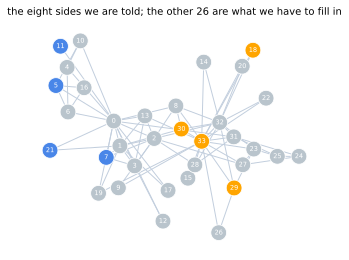

<Axes: title={'center': 'the eight sides we are told; the other 26 are what we have to fill in'}>

In [3]:
centrality = {
    "degree": nx.degree_centrality(G),
    "eigenvector": nx.eigenvector_centrality(G),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G),
}

# Standardised, because betweenness spans two orders of magnitude more than the
# others and would otherwise decide every distance on its own.
X = np.array([[m[n] for m in centrality.values()] for n in members],
             dtype=np.float32)
X = (X - X.mean(0)) / X.std(0)
features, labels = torch.tensor(X), torch.tensor(y)


def labelled(seed, per_side=4):
    """The members whose side we are told: four from each faction.

    Drawn exactly as module 1 drew it -- same generator, same call -- so the
    table below reproduces the numbers the room already saw rather than numbers
    close to them. The mask is drawn here and handed to every model: a model
    that picks its own eight is not in the same experiment as the others.
    """
    torch.manual_seed(seed)
    mask = torch.zeros(len(members), dtype=torch.bool)
    for side in (0, 1):
        of_side = (labels == side).nonzero().flatten()
        mask[of_side[torch.randperm(len(of_side))[:per_side]]] = True
    return mask


known = labelled(0)
print(f"told: {int(known.sum())} members  |  to guess: {int((~known).sum())}")
# Grey is a side we were not told. Eight points of colour in a grey club is the
# whole starting position, and it needs no outline on top of it.
club(G, pos, sides(y, known.numpy()),
     "the eight sides we are told; the other 26 are what we have to fill in")


In [4]:
import torch.nn.functional as F
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from torch.nn import Linear
from torch_geometric.nn import GCNConv

# Both directions. The club is undirected and GCNConv reads the edge list as
# given, so listing each friendship once would let messages flow one way only.
edge_index = torch.tensor([[u, v] for u, v in G.edges()]
                          + [[v, u] for u, v in G.edges()]).t().contiguous()
class MLP(torch.nn.Module):
    """Two layers, each member on their own.

    `forward` takes `edge_index` and ignores it. That is the whole experiment:
    the two networks are called identically, trained identically and scored
    identically, so any difference between them comes from the edges.
    """

    def __init__(self, columns, hidden=16):
        super().__init__()
        self.lin1, self.lin2 = Linear(columns, hidden), Linear(hidden, 2)

    def forward(self, x, edge_index):
        return self.lin2(self.lin1(x).relu())


class GCN(torch.nn.Module):
    """The same two layers, each one now averaging over the neighbours first."""

    def __init__(self, columns, hidden=16):
        super().__init__()
        self.conv1, self.conv2 = GCNConv(columns, hidden), GCNConv(hidden, 2)

    def forward(self, x, edge_index):
        return self.conv2(self.conv1(x, edge_index).relu(), edge_index)


def guesses_net(Model, known, seed, epochs=200):
    torch.manual_seed(seed)
    model = Model(X.shape[1])
    optimiser = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for _ in range(epochs):
        optimiser.zero_grad()
        F.cross_entropy(model(features, edge_index)[known], labels[known]).backward()
        optimiser.step()
    with torch.no_grad():
        return model(features, edge_index).argmax(1).numpy()


def guesses_table(model, known, seed):
    told = known.numpy()
    model.fit(X[told], y[told])
    return model.predict(X)


def scored(guess, known):
    """Accuracy over the members the model was NOT told about.

    Scoring the eight it was given would measure nothing: every model here gets
    them right by construction, and including them lifts all four by the same
    amount while hiding the only 26 that matter.
    """
    told = known.numpy()
    return (guess[~told] == y[~told]).mean()


# Ten draws of the eight, as in module 1, and every model sees the same eight in
# each draw. The spread is printed next to each mean and it is large: one draw to
# the next this table moves by about 0.1, which is worth knowing before reading
# any single number off it as a property of the method.
MODELS = [
    ("logistic regression", "no",
     lambda k, s: guesses_table(LogisticRegression(max_iter=1000), k, s)),
    ("random forest", "no",
     lambda k, s: guesses_table(RandomForestClassifier(n_estimators=300,
                                                       random_state=0), k, s)),
    ("MLP", "no", lambda k, s: guesses_net(MLP, k, s)),
    ("GCN", "YES", lambda k, s: guesses_net(GCN, k, s)),
]

SEEDS = 10

print(f"{'model':24s} {'sees the edges':>15s} {'accuracy':>16s} {'of 26':>8s}")
print("-" * 66)
for name, sees, run in MODELS:
    scores = [scored(run(labelled(seed), seed), labelled(seed))
              for seed in range(SEEDS)]
    print(f"{name:24s} {sees:>15s} "
          f"{np.mean(scores):>10.2f} ±{np.std(scores):.2f} "
          f"{np.mean(scores) * 26:>8.0f}")


/private/tmp/claude-501/-Users-giuseppefutia-Desktop-code-kgtp/211e9142-fbf2-4c28-97e3-4461866db636/scratchpad/venv-verifica/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


model                     sees the edges         accuracy    of 26
------------------------------------------------------------------
logistic regression                   no       0.44 ±0.06       12


random forest                         no       0.51 ±0.11       13


MLP                                   no       0.49 ±0.11       13


GCN                                  YES       0.75 ±0.11       19


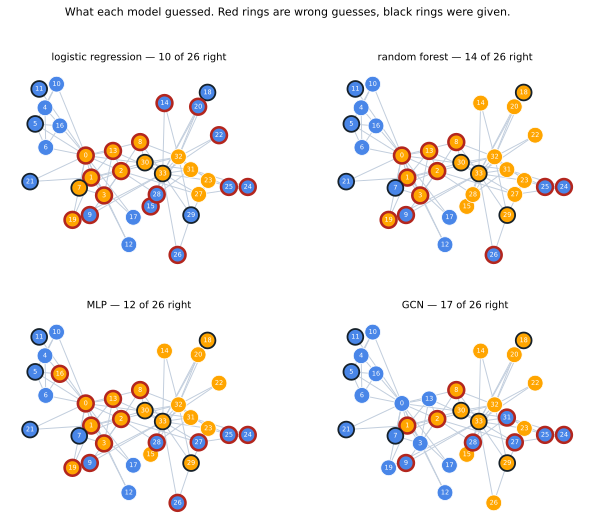

In [5]:
# One draw of the eight -- seed 0 -- so the four pictures are comparable. The
# table above averages ten; a figure cannot average, so it says which draw it is.
known = labelled(0)
told = known.numpy()

fig, axes = plt.subplots(2, 2, figsize=(10.4, 8.2))
for (name, _, run), ax in zip(MODELS, axes.ravel()):
    guess = run(known, 0)
    wrong = [n for n, (g, t) in enumerate(zip(guess, y)) if g != t and not told[n]]
    club(G, pos, sides(guess),
         f"{name} — {int(scored(guess, known) * 26)} of 26 right",
         ax=ax, ring=[n for n in members if told[n]], wrong=wrong)
fig.suptitle("What each model guessed. Red rings are wrong guesses, black rings were given.",
             fontsize=11)
plt.show()


## Same eight, same twenty-six, one model allowed to look

Every model was handed the same eight members and scored on the same 26. Three
land near a coin flip; the GCN keeps 19. It had the same four columns — what it
got was `edge_index`, which the MLP was handed and told to ignore.

**The red rings say where it still fails.** Over ten draws, the members the GCN
gets wrong have **0.25** of their friendships crossing into the other faction,
against **0.11** across the club. It misses at the border. The other three miss
at 0.12 — everywhere.

Thirty-four members is no place to conclude anything in general, and this graph
was handed down because it splits cleanly. What generalises is the trade:
**structure buys you labels**. The rest of the session asks whether it buys
anything on a graph nobody chose for us.


## What the edges actually do

The GCN's 19 came from `edge_index`. So before going anywhere near Chicago,
here is exactly what one layer does with it — on one member, with no training in
sight.

Member 13 has five friends: 0, 1, 2, 3 and 33. A layer of `GCNConv` does two
things to him, in this order:

1. **mix** his own four columns with his five friends' four columns, as a
   weighted average;
2. **transform** the result with one matrix, which is the part that gets learned.

Only step 2 is learned. The weights of step 1 come from the graph itself.


member 13 — friends: [0, 1, 2, 3, 33]

how one GCN layer mixes them
   itself     weight 0.167   (5 friends of its own)
   friend 0   weight 0.099   (16 friends of its own)
   friend 1   weight 0.129   (9 friends of its own)
   friend 2   weight 0.123   (10 friends of its own)
   friend 3   weight 0.154   (6 friends of its own)
   friend 33  weight 0.096   (17 friends of its own)

one layer on member 13
   by hand    [-1.8596  0.1092  1.7591]
   GCNConv    [-1.8596  0.1092  1.7591]
   largest difference anywhere: 1.6e-07


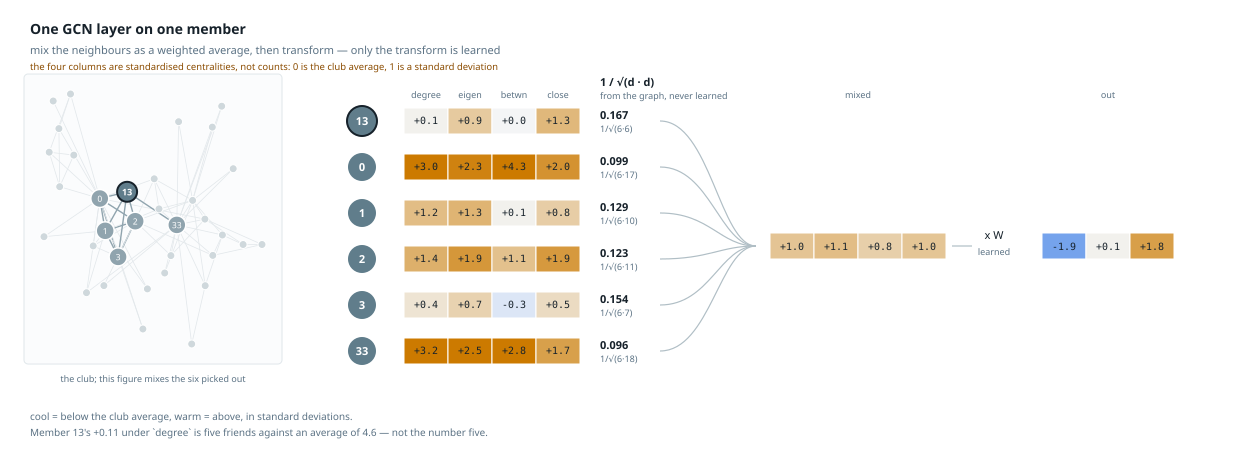

In [6]:
member = 13
friends = list(G.neighbors(member))

# GCNConv's mixing weights, written out: add a self-loop to every node, then
# divide each edge by the square root of the degree at both of its ends.
A = torch.tensor(nx.to_numpy_array(G, nodelist=members, weight=None),
                 dtype=torch.float32)
with_self = A + torch.eye(len(members))
degree = with_self.sum(1)
mix = with_self / (degree.sqrt().unsqueeze(1) * degree.sqrt().unsqueeze(0))

print(f"member {member} — friends: {friends}\n")
print("how one GCN layer mixes them")
for j in [member] + friends:
    who = "itself" if j == member else f"friend {j}"
    print(f"   {who:10s} weight {mix[member, j]:.3f}   "
          f"({G.degree(j)} friends of its own)")

# The same layer, run by PyTorch Geometric and rebuilt by hand. `lin.weight` is
# the matrix of step 2 and the only thing training would change; nothing here is
# trained, which is the point -- the mixing is not learned.
torch.manual_seed(0)
layer = GCNConv(X.shape[1], 3)
with torch.no_grad():
    theirs = layer(features, edge_index)
    ours = mix @ (features @ layer.lin.weight.T) + layer.bias

print(f"\none layer on member {member}")
print(f"   by hand    {np.round(ours[member].numpy(), 4)}")
print(f"   GCNConv    {np.round(theirs[member].numpy(), 4)}")
print(f"   largest difference anywhere: "
      f"{(theirs - ours).abs().max().item():.1e}")

# Drawn from the arrays above, so the picture cannot drift from the numbers.
mixed = (mix[member] @ features).numpy()
display(SVG(forward_pass(
    member, friends,
    {n: X[n] for n in [member] + friends},
    {n: float(mix[member, n]) for n in [member] + friends},
    mixed, theirs[member].numpy(), graph=G, pos=pos)))


## It is a weighted average

The two numbers agree to seven decimal places, so there is nothing hidden in
`GCNConv`: it mixes, then multiplies.

And look at which friends count. Member 13's two smallest weights, **0.099** and
**0.096**, go to members **0** and **33** — the instructor and the president, the
two best-connected people in the club. A friend who is friends with everybody
tells you least about which side you are on, and the degree in the denominator
is what says so.

That is the whole mechanism, and it is the reason the rest of this session is
possible: **if mixing the neighbours is a weighted average, then a query can
compute it.** `avg()` over a one-hop neighbourhood is a plainer version of the
same step — no weights, no training, no torch.

Which raises the question the next three sections are built on. On a real graph,
how much of what a graph neural network buys you is the mixing, and how much is
the part it learned?


## Chicago, and who stops filing

The karate club was handed down because it splits cleanly. This graph was not
handed to anyone: it is the one modules 3 to 5 built out of four public files
from the City of Chicago, and nobody chose it to make a method look good.

A licence register sees you when you file something. Most of its holders file
again within a few years — a new permit, a second code, another shopfront. Some
stop. **Administrative continuity is a reasonable proxy for how alive the
commercial side of a city is**, and it is one of the few things a register can
measure about itself.

> I am an owner of record in **2015**. Between **2018 and 2021**, will a new
> licence appear on something I hold — or will I go quiet?

Of 69,822 owners active in 2015, **26,257 file nothing at all** in those three
years.

**What a city does with that.** An owner about to go quiet is, more often than
not, a form that did not get filed rather than a business that closed — and this
register proves it on itself: Chicago suspended licence expiries in 2020, and
**42,876** of them rebounded into 2021 against **25,186** the year before. The
file measures paperwork before it measures the economy. So the interventions are
the ordinary ones: a reminder before a renewal falls due, help with the
paperwork, a visit to a block that is emptying, somewhere to put a small-business
desk. A wrong guess costs a phone call nobody needed.

It is not a score on a person and it decides nothing about them — the same line
this course drew in module 4 when it refused to rank vendors.

Thirty-four members became 69,822 owners, and four columns became thirty.


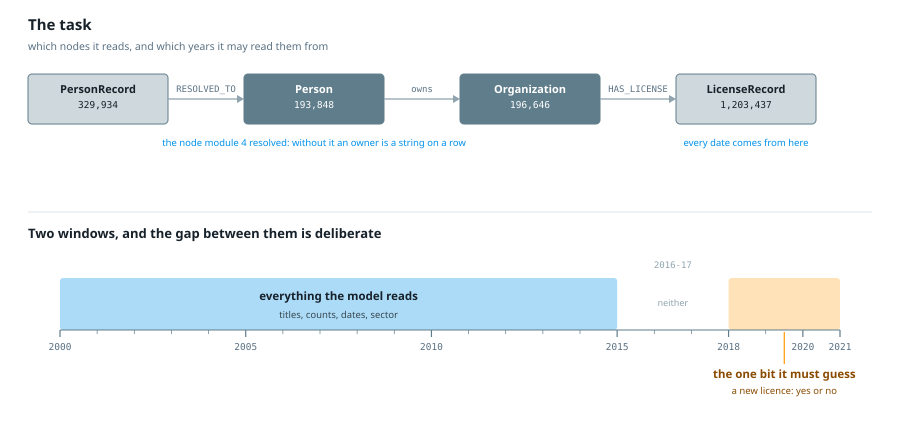

In [7]:
import os
import time

import pandas as pd
from neo4j import GraphDatabase

driver = GraphDatabase.driver(
    os.environ.get("NEO4J_URI", "bolt://localhost:7687"),
    auth=(os.environ.get("NEO4J_USER", "neo4j"),
          os.environ.get("NEO4J_PASSWORD", "password")))

# The database is named, not left to the server default. The default database on
# an instance that has been used for anything else holds another graph, and
# asking the wrong one does not raise: the queries below return, with numbers
# from whatever is in there. Checked 19/11/2026 -- the default here answered with
# 53,686 licence records against this one's 1,203,437.
DATABASE = os.environ.get("NEO4J_DATABASE", "kgtp")

SHAPE = """
RETURN {
  PersonRecord:  COUNT { MATCH (:PersonRecord {source:'OWNERS'}) },
  Person:        COUNT { MATCH (:PersonRecord {source:'OWNERS'})
                               -[:RECORD_RESOLVED_TO]->(p:Person)
                         RETURN DISTINCT p },
  Organization:  COUNT { MATCH (:Organization {source:'LICENSES'}) },
  LicenseRecord: COUNT { MATCH (:LicenseRecord) }
} AS counts
"""

with driver.session(database=DATABASE) as session:
    shape = session.run(SHAPE).single()["counts"]

display(SVG(chicago_task(shape)))


Ahmad Alsilwadi           8 filings to 2015   2018-21: nothing
Toula Anastos             4 filings to 2015   2018-21: [2018, 2020]
Clara Hudson             12 filings to 2015   2018-21: nothing
A. Elizabeth Ortner       4 filings to 2015   2018-21: nothing


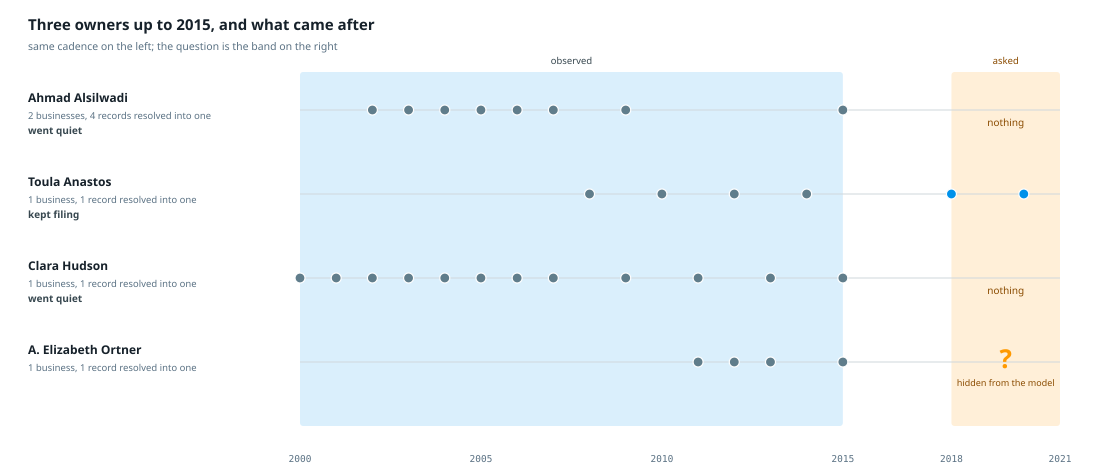

In [8]:
# Four owners of the 69,822, keyed by the cluster module 4 resolved and not by
# name. A name is not a key here: looking up "Charles Roger Clough" lands on a
# cluster with one licence in 2022, while the cluster this notebook had selected
# under that name holds nine businesses and sixteen licences. Entity resolution
# merges several records into one person, and the name shown is only one of hers.
#
# How they were chosen, 26/11/2026: all four are in the held-out third under the
# component split, the trained engine is right about all four, and each cluster
# carries exactly one spelling of its name -- so the lookup in the last section
# finds the same person this figure draws. Three earlier picks failed that test:
# they sat in the training half and the engine was wrong about all three.
# The middle two are the point, and they are a pair: one business each, and the
# one with a THIRD of the filings is the one that carries on. Whatever separates
# them, it is not how much paperwork they had already done.
SHOWN = [
    ("L105682",   "went quiet"),   # Ahmad Alsilwadi -- 8 filings, then nothing
    ("R3219262",  "kept filing"),  # Toula Anastos -- 4 filings, and carries on
    ("R3201980",  "went quiet"),   # Clara Hudson -- 12 filings, then nothing
    ("R3246868",  None),           # A. Elizabeth Ortner -- the last section asks
]

HISTORIES = """
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
  WHERE p.clusterId = $cluster
MATCH (o:Organization {source:'LICENSES'}) WHERE o.id = r.employerId
MATCH (o)-[:ORG_HAS_LICENSE]->(l:LicenseRecord)
WITH collect(DISTINCT r.fullName)[0] AS name, count(DISTINCT r) AS records,
     count(DISTINCT o) AS businesses,
     collect(DISTINCT toInteger(right(l.startDate,4))) AS years
RETURN name, records, businesses,
       [y IN years WHERE y >= 2000 AND y <= 2015] AS before_years,
       [y IN years WHERE y >= 2018 AND y <  2021] AS window_years
"""

rows = []
with driver.session(database=DATABASE) as session:
    for cluster, answer in SHOWN:
        found = dict(session.run(HISTORIES, cluster=cluster).single())
        rows.append({"name": found["name"], "businesses": found["businesses"],
                     "records": found["records"],
                     "before": sorted(found["before_years"]),
                     "window": sorted(found["window_years"]),
                     "answer": answer})
        print(f"{found['name']:24s} {len(found['before_years']):>2} filings to 2015"
              f"   2018-21: {sorted(found['window_years']) or 'nothing'}")

display(SVG(owner_timelines(rows)))


In [9]:
import time

# One row per (owner, business). Everything is cut at 2015 except `opened`,
# which is the label and looks at 2018-2021 -- the only column that may.
OWNERS = """
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
MATCH (o:Organization {source:'LICENSES'}) WHERE o.id = r.employerId
MATCH (o)-[:ORG_HAS_LICENSE]->(l:LicenseRecord)
WITH p.clusterId AS person, r.title AS title, o.id AS business,
     min(toInteger(right(l.startDate,4)))  AS first_year,
     count(CASE WHEN toInteger(right(l.startDate,4)) >= 2012
                 AND toInteger(right(l.startDate,4)) <  2015 THEN 1 END) AS recent,
     max(CASE WHEN toInteger(right(l.startDate,4)) <= 2015
                AND toInteger(right(l.endDate,4))   >= 2015 THEN 1 ELSE 0 END) AS active,
     max(CASE WHEN toInteger(right(l.startDate,4)) >= 2018
                AND toInteger(right(l.startDate,4)) <  2021 THEN 1 ELSE 0 END) AS opened
RETURN person, title, business, first_year, recent, active, opened
"""

# What each business was by 2015. The owners have almost no attributes of their
# own, so this is where a neighbour's information comes from.
BUSINESSES = """
MATCH (o:Organization {source:'LICENSES'})-[:ORG_HAS_LICENSE]->(l:LicenseRecord)
  WHERE toInteger(right(l.startDate,4)) <= 2015
WITH o.id AS business, count(l) AS licences, count(DISTINCT l.code) AS kinds,
     min(toInteger(right(l.startDate,4))) AS first_year,
     collect(DISTINCT l.code)[0] AS code
RETURN business, licences, kinds, first_year, code
"""

started = time.perf_counter()
with driver.session(database=DATABASE) as session:
    owners = pd.DataFrame([dict(r) for r in session.run(OWNERS)])
    businesses = pd.DataFrame([dict(r) for r in session.run(BUSINESSES)])

cohort = owners.groupby("person")[["active", "opened"]].max()
cohort = cohort[cohort["active"] == 1]
print(f"owners {owners['person'].nunique():,}   "
      f"businesses {owners['business'].nunique():,}   "
      f"titles {owners['title'].nunique()}   "
      f"({time.perf_counter() - started:.0f} s for both queries)")
quiet = len(cohort) - int(cohort["opened"].sum())
print(f"cohort {len(cohort):,} of {owners['person'].nunique():,} owners "
      f"— those with a business still live in 2015")
print(f"   {int(cohort['opened'].sum()):,} filed again by 2021 "
      f"({cohort['opened'].mean():.1%})      {quiet:,} did not   "
      f"->  the two classes")

# The register measuring paperwork rather than the economy, on itself: Chicago
# suspended licence expiries in 2020, and they landed in 2021 instead. Counted
# here because the prose above says the numbers, and a number in prose that no
# cell produces is a number a reader cannot check.
EXPIRIES = """
MATCH (l:LicenseRecord) WHERE toInteger(right(l.endDate,4)) IN [2020, 2021]
RETURN toInteger(right(l.endDate,4)) AS year, count(l) AS expiries ORDER BY year
"""
with driver.session(database=DATABASE) as session:
    expiries = {row["year"]: row["expiries"] for row in session.run(EXPIRIES)}
print(f"licences expiring in 2020: {expiries[2020]:,}      "
      f"in 2021: {expiries[2021]:,}   ->  the suspension, visible in the file")


owners 193,848   businesses 196,616   titles 23   (11 s for both queries)
cohort 69,822 of 193,848 owners — those with a business still live in 2015
   43,565 filed again by 2021 (62.4%)      26,257 did not   ->  the two classes


licences expiring in 2020: 25,186      in 2021: 42,876   ->  the suspension, visible in the file


## From rows to a graph

**Those two queries were the data preparation.** There is no other step: no
export, no intermediate file, no second pass over the graph. What is left is
bookkeeping — and the bookkeeping is where it goes wrong.

| what the query returned | what pandas holds | what the network is handed |
|---|---|---|
| one row per (owner, business), with the label | `owners` | `edge_index` — 2 × 575,034 |
| what each business was by 2015 | `businesses` | `x` — 390,464 × 52 |
| the label column of the first query | `cohort` | `y` — 69,822, plus the index saying which nodes those are |

`edge_index` carries twice the 287,517 pairs because every edge goes in both
directions, and `y` is shorter than `x` because most nodes have no answer.

**The integers are the part that goes wrong.** Every owner and every business
gets a position in one array, and from then on a node *is* that position — the
owner's id survives only to look one up again. Two numbering schemes mixed
together give a graph that trains without complaint and means nothing, which is
why the cell below ends in two assertions rather than a print.

The owner's twenty-seven columns: her title, one of 23; how many businesses she
holds; how long she has held one; and whether she already started something
between 2012 and 2015. Nothing about her age, her trade or her income — the
register does not have it. **Everything else she is, in this graph, is what she
owns.**


In [10]:
from sklearn.model_selection import train_test_split
from collections import Counter

# Owners first, businesses after: one array of nodes, and from here a node is a
# position in it. Keeping two numbering schemes is the mistake this cell exists
# to avoid.
people = sorted(owners["person"].unique())
shops = sorted(owners["business"].unique())
at = {k: i for i, k in enumerate(people)}
at.update({k: len(people) + i for i, k in enumerate(shops)})

titles = sorted(t for t in owners["title"].dropna().unique())
column_of = {t: i for i, t in enumerate(titles)}
OWN_COLUMNS = len(titles) + 4

by_person = owners.groupby("person")
derived = pd.DataFrame({"businesses": by_person["business"].nunique(),
                        "first": by_person["first_year"].min(),
                        "recent": by_person["recent"].sum()})

owner_block = np.zeros((len(people), OWN_COLUMNS), dtype=np.float32)
for title, rows in owners.dropna(subset=["title"]).groupby("title"):
    owner_block[[at[p] for p in rows["person"].unique()], column_of[title]] = 1.0
where = np.array([at[p] for p in derived.index])
# Capped, then scaled to [0, 1]. Uncapped, a handful of owners with hundreds of
# licences would flatten everybody else onto the same value.
owner_block[where, len(titles) + 0] = np.minimum(derived["businesses"], 20) / 20
owner_block[where, len(titles) + 1] = np.clip(2015 - derived["first"].fillna(2015),
                                              0, 40) / 40
owner_block[where, len(titles) + 2] = (derived["recent"] > 0).astype(np.float32)
owner_block[where, len(titles) + 3] = np.minimum(derived["recent"], 10) / 10

top_codes = [c for c, _ in Counter(businesses["code"]).most_common(20)]
code_of = {c: i for i, c in enumerate(top_codes)}
shop_block = np.zeros((len(shops), 3 + len(top_codes) + 1), dtype=np.float32)
known = businesses[businesses["business"].isin(at)]
rows = np.array([at[b] - len(people) for b in known["business"]])
shop_block[rows, 0] = np.clip(2015 - known["first_year"], 0, 40) / 40
shop_block[rows, 1] = np.minimum(known["licences"], 50) / 50
shop_block[rows, 2] = np.minimum(known["kinds"], 10) / 10
for code, rows_of in known.groupby("code"):
    shop_block[[at[b] - len(people) for b in rows_of["business"]],
               3 + code_of.get(code, len(top_codes))] = 1.0

# One block per node type, and a flag saying which. An owner has zeros where a
# business has its columns and the other way round: the standard way to put two
# kinds of node in one homogeneous graph without pretending their features are
# the same thing.
features = np.zeros((len(people) + len(shops),
                     OWN_COLUMNS + shop_block.shape[1] + 1), dtype=np.float32)
features[:len(people), :OWN_COLUMNS] = owner_block
features[len(people):, OWN_COLUMNS:OWN_COLUMNS + shop_block.shape[1]] = shop_block
features[:len(people), -1] = 1.0

owns = np.array(sorted({(at[p], at[b])
                        for p, b in zip(owners["person"], owners["business"])}),
                dtype=np.int64)
knowable = np.array([at[p] for p in cohort.index])
label = cohort["opened"].to_numpy().astype(np.int64)

assert owns.max() < len(features), "an edge points past the end of the node array"
assert (knowable < len(people)).all(), "a labelled node is not an owner"
print(f"nodes {len(features):,}  = {len(people):,} owners + {len(shops):,} businesses")
print(f"columns {features.shape[1]}     = {OWN_COLUMNS} owner + "
      f"{shop_block.shape[1]} business + 1 type flag")
print(f"edges {len(owns):,}  = one per (owner, business); "
      f"no owner-to-owner edge exists")
print(f"labelled {len(knowable):,} of {len(features):,} nodes "
      f"({len(knowable)/len(features):.0%}) — a business carries no answer at all,"
      f" {label.mean():.1%} of the owners filed again")


def three_slices(seed):
    """Test, and a validation slice carved out of the training half.

    Choosing the epoch by looking at the test set is model selection on the
    thing being reported, and it flatters only the models that have epochs --
    which here means the two networks and neither of the three above them.
    """
    train, test = train_test_split(np.arange(len(knowable)), test_size=0.3,
                                   random_state=seed, stratify=label)
    train, valid = train_test_split(train, test_size=0.2, random_state=seed,
                                    stratify=label[train])
    return train, valid, test

train, valid, test = three_slices(0)
print(f"split {len(train):,} train + {len(valid):,} validation + "
      f"{len(test):,} test = {len(train) + len(valid) + len(test):,}")


nodes 390,464  = 193,848 owners + 196,616 businesses
columns 52     = 27 owner + 24 business + 1 type flag
edges 287,517  = one per (owner, business); no owner-to-owner edge exists
labelled 69,822 of 390,464 nodes (18%) — a business carries no answer at all, 62.4% of the owners filed again
split 39,100 train + 9,775 validation + 20,947 test = 69,822


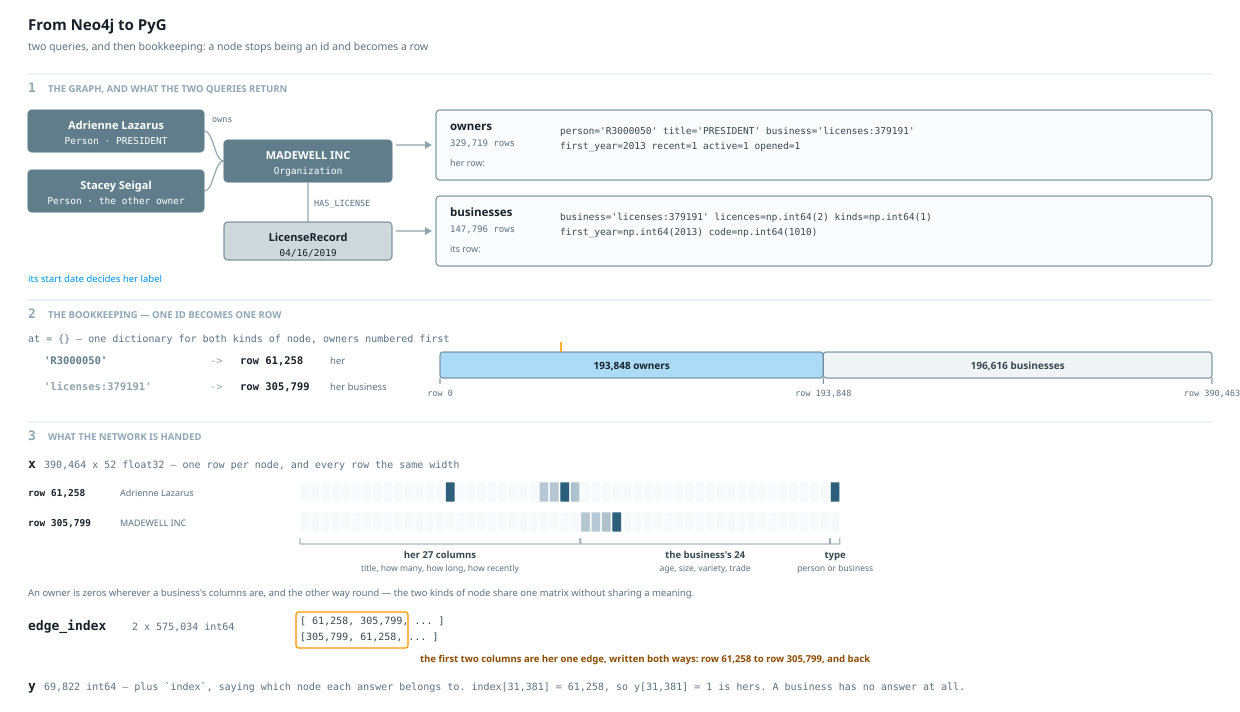

In [11]:
# One real owner, by cluster id, so the left of the figure is a fragment of this
# graph and not a drawing of one. Adrienne Lazarus: one business, one co-owner,
# one spelling of her name, and a licence from 2013 -- so she is in the 2015
# snapshot the model reads. Her label is 1, and the date that decides it is the
# filing in the window, which is the date the figure shows.
#
# `min(l.startDate)` would be wrong here and silently: the dates are strings as
# `MM/DD/YYYY`, so the smallest string is the earliest *month*, not the earliest
# year -- asked for hers it answered 02/26/2021 while her first licence is from
# April 2013. Every date comparison in this notebook goes through the year.
FRAGMENT = """
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
  WHERE p.clusterId = $cluster
MATCH (o:Organization {source:'LICENSES'}) WHERE o.id = r.employerId
MATCH (o)-[:ORG_HAS_LICENSE]->(l:LicenseRecord)
OPTIONAL MATCH (other:PersonRecord {source:'OWNERS'})
  WHERE other.employerId = o.id AND other.fullName <> r.fullName
WITH r, o, l, toInteger(right(l.startDate,4)) AS year,
     collect(DISTINCT other.fullName) AS others
WITH r.fullName AS owner, r.title AS title, o.name AS business, o.id AS bid,
     collect(CASE WHEN year >= 2018 AND year < 2021 THEN l.startDate END) AS window,
     min(year) AS first_year, others
RETURN owner, title, business, bid, first_year,
       [d IN window WHERE d IS NOT NULL] AS window,
       coalesce(others[0], "(no other owner)") AS co_owner
"""

with driver.session(database=DATABASE) as session:
    fragment = dict(session.run(FRAGMENT, cluster="R3000050").single())

# The earliest of her filings in the window, sorted here rather than in Cypher:
# `MM/DD/YYYY` sorts by month as a string, and the day the sort happens in the
# database is the day nobody notices.
fragment["started"] = sorted(fragment.pop("window"),
                             key=lambda d: (d[6:], d[:2], d[3:5]))[0]

# Her own row out of the arrays the next cell trains on -- not retyped into the
# drawing. If the bookkeeping in the cell above were wrong, these numbers would
# be wrong here too, which is the only way a figure can check it.
her = at["R3000050"]
shop = at[fragment["bid"]]
label_at = int(np.flatnonzero(knowable == her)[0])

both = np.concatenate([owns, owns[:, ::-1]])
forth = int(np.flatnonzero((both[:, 0] == her) & (both[:, 1] == shop))[0])
back = int(np.flatnonzero((both[:, 0] == shop) & (both[:, 1] == her))[0])

GROUPS = [(0, OWN_COLUMNS - 1, f"her {OWN_COLUMNS} columns",
           "title, how many, how long, how recently"),
          (OWN_COLUMNS, features.shape[1] - 2,
           f"the business's {shop_block.shape[1]}", "age, size, variety, trade"),
          (features.shape[1] - 1, features.shape[1] - 1, "type",
           "person or business")]

display(SVG(neo4j_to_pyg(
    {"owner_rows": len(owners), "business_rows": len(businesses),
     "nodes": len(features), "columns": features.shape[1], "people": len(people),
     "edges": len(owns), "labelled": len(knowable)},
    {**fragment,
     "cluster": "R3000050", "business_id": fragment["bid"],
     "owner_index": her, "business_index": shop,
     "owner_row": [
         f"person='R3000050'  title='{fragment['title']}'  "
         f"business='{fragment['bid']}'",
         f"first_year={fragment['first_year']}  "
         f"recent={int(owners.loc[owners['person'] == 'R3000050', 'recent'].iloc[0])}"
         f"  active={int(owners.loc[owners['person'] == 'R3000050', 'active'].iloc[0])}"
         f"  opened={int(owners.loc[owners['person'] == 'R3000050', 'opened'].iloc[0])}"],
     "business_row": [
         "  ".join(f"{k}={businesses.loc[businesses['business'] == fragment['bid'], k].iloc[0]!r}"
                   for k in ("business", "licences", "kinds")),
         "  ".join(f"{k}={businesses.loc[businesses['business'] == fragment['bid'], k].iloc[0]!r}"
                   for k in ("first_year", "code"))],
     "x_owner": features[her].tolist(),
     "x_business": features[shop].tolist(),
     "groups": GROUPS,
     "edge_columns": [[int(both[forth, 0]), int(both[back, 0])],
                      [int(both[forth, 1]), int(both[back, 1])]],
     "label_at": label_at, "label": int(label[label_at])})))


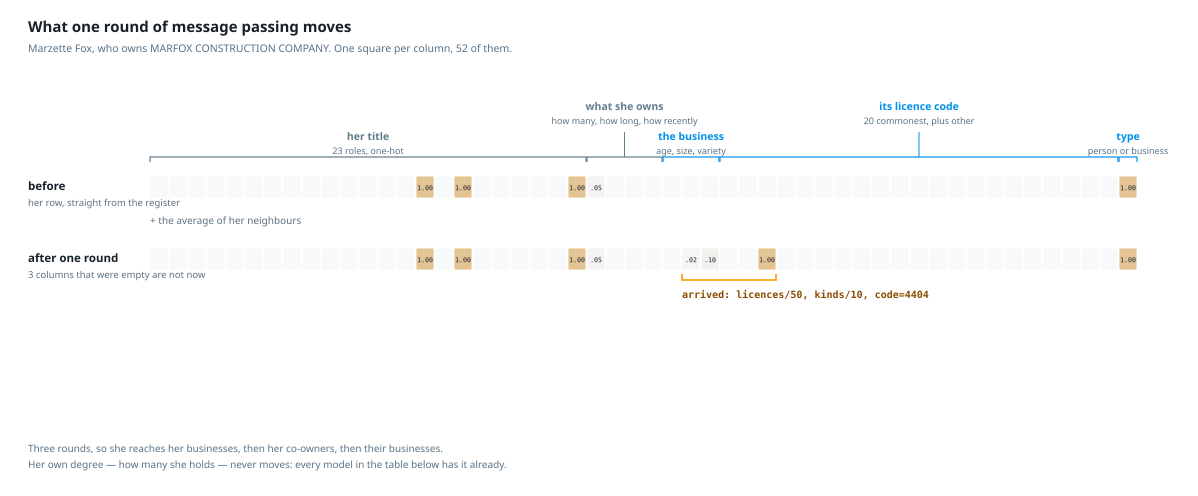

In [12]:
# The columns, in the order they sit in the array. Built from the same lists the
# cell above used, so the names cannot drift from the numbers they label.
COLUMN_NAMES = ([f"title={t}" for t in titles]
                + ["businesses/20", "years/40", "filed_12_15", "filings/10"]
                + ["age/40", "licences/50", "kinds/10"]
                + [f"code={c}" for c in top_codes] + ["code=other", "is_person"])

# An owner with exactly one business, so "the average of her neighbours" is just
# her business and the arithmetic is visible rather than merely true.
holdings = owners.groupby("person")["business"].nunique()
alone = holdings[holdings == 1].index[3]
her, hers = at[alone], at[owners[owners["person"] == alone]["business"].iloc[0]]
neighbours = owns[owns[:, 0] == her][:, 1]

# Her name and her shop's, not `R3012345` and `licenses:400176`. The ids are how
# the graph addresses them and not how a room reads them.
NAMED = """
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
  WHERE p.clusterId = $cluster
MATCH (o:Organization {source:'LICENSES'}) WHERE o.id = $business
RETURN collect(DISTINCT r.fullName)[0] AS owner, o.name AS business
"""
with driver.session(database=DATABASE) as session:
    named = dict(session.run(NAMED, cluster=alone,
                             business=owners[owners["person"] == alone]["business"]
                             .iloc[0]).single())

# The categories, spelled out rather than inferred from the names: a figure that
# guesses where the title block ends mislabels itself the day a title appears.
GROUPS = [
    (0, len(titles) - 1, "her title", f"{len(titles)} roles, one-hot"),
    (len(titles), OWN_COLUMNS - 1, "what she owns",
     "how many, how long, how recently"),
    (OWN_COLUMNS, OWN_COLUMNS + 2, "the business",
     "age, size, variety"),
    (OWN_COLUMNS + 3, features.shape[1] - 2, "its licence code",
     f"{len(top_codes)} commonest, plus other"),
    (features.shape[1] - 1, features.shape[1] - 1, "type", "person or business"),
]

display(SVG(message_passing(
    named["owner"], {"before": features[her],
                     "after": features[her] + features[neighbours].mean(0)},
    COLUMN_NAMES, groups=GROUPS, business=named["business"])))


## What the training actually does

Three rounds of message passing, then one number per owner. The part that is
easy to miss is which rows are allowed to touch what.


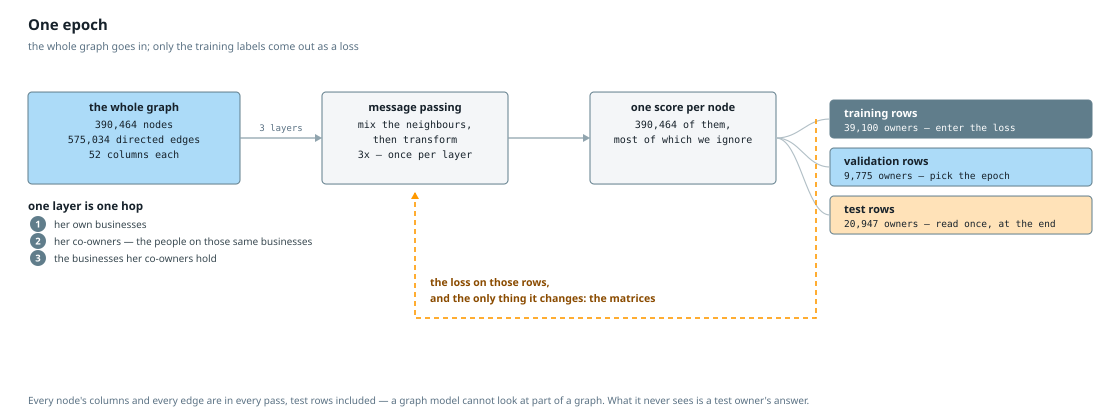

In [13]:
import torch.nn as nn
from torch_geometric.nn import SAGEConv

class Net(nn.Module):
    """Three layers of message passing, then one number per node.

    A layer is a hop: the first reaches her businesses, the second her
    co-owners, the third their businesses. "Round", "layer" and "hop" are
    three words for the same count, and from here the word is **layer** --
    what the papers and PyG call it.

    `edge_index` is an argument rather than a field, so the same class with the
    same parameter count runs with the graph and without it. That is the control
    the rest of this session turns on.
    """

    def __init__(self, columns, hidden=256, layers=3, dropout=0.2):
        super().__init__()
        self.layers = nn.ModuleList(
            [SAGEConv(columns if i == 0 else hidden, hidden) for i in range(layers)])
        self.head = nn.Linear(hidden, 1)
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.layers:
            x = F.dropout(F.relu(conv(x, edge_index)), self.dropout, self.training)
        return self.head(x).squeeze(-1)


# A layer is a hop, and `layers` is read off the model rather than written here.
# On this graph the hops alternate, because there is no owner-to-owner edge: a
# co-owner is two layers away and never one.
REACH = ["her own businesses",
         "her co-owners — the people on those same businesses",
         "the businesses her co-owners hold"]

display(SVG(training_loop(
    {"nodes": len(features), "edges": 2 * len(owns),
     "columns": features.shape[1],
     "train": len(three_slices(0)[0]), "valid": len(three_slices(0)[1]),
     "test": len(three_slices(0)[2])},
    layers=len(Net(features.shape[1]).layers), reach=REACH)))


In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch_geometric.nn import SAGEConv

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
all_features = torch.tensor(features).to(device)
# Both directions again, and for the same reason as the club.
both_ways = torch.tensor(np.concatenate([owns, owns[:, ::-1]]).T.copy()).to(device)
no_edges = torch.zeros((2, 0), dtype=torch.long, device=device)
own_columns = features[knowable][:, :OWN_COLUMNS]


def train_net(seed, edge_index, epochs=60):
    torch.manual_seed(seed)
    train, valid, test = three_slices(seed)
    model = Net(features.shape[1]).to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=0.01)
    rows = torch.tensor(knowable[train]).to(device)
    answers = torch.tensor(label[train], dtype=torch.float32).to(device)
    best_valid, test_there = 0.0, 0.0
    for epoch in range(epochs):
        model.train()
        optimiser.zero_grad()
        F.binary_cross_entropy_with_logits(
            model(all_features, edge_index)[rows], answers).backward()
        optimiser.step()
        if epoch % 10 == 0 or epoch == epochs - 1:
            model.eval()
            with torch.no_grad():
                scores = model(all_features, edge_index).cpu().numpy()
            here = roc_auc_score(label[valid], scores[knowable[valid]])
            if here > best_valid:
                best_valid = here
                test_there = roc_auc_score(label[test], scores[knowable[test]])
    return test_there


def run_with(seed, slicer):
    """Run every row of ROWS under a different way of slicing the owners.

    The slicer is an argument because the next section changes it and changes
    nothing else: a comparison that moved the split *and* the columns would be
    two changes at once, which is the mistake this module is about.
    """
    global three_slices
    before, three_slices = three_slices, slicer
    try:
        return {name: run(seed) for name, _, run in ROWS}
    finally:
        three_slices = before


def train_table(make, seed, scale=False):
    train, _, test = three_slices(seed)
    fit, score = own_columns[train], own_columns[test]
    if scale:
        scaler = StandardScaler().fit(fit)
        fit, score = scaler.transform(fit), scaler.transform(score)
    model = make().fit(fit, label[train])
    return roc_auc_score(label[test], model.predict_proba(score)[:, 1])


# Sixty epochs here, four hundred in the full run. Sixty is what fits in a
# ninety-minute session next to everything else in this notebook, and it is
# enough to see the ranking; it is not enough to see the size of the gap, which
# is why the column beside it exists.
#
# What the full run measured: four seeds, 400 epochs, 19/11/2026. Reproduce it
# with the two scripts this course ships, which build the same arrays this
# notebook builds and train the same network:
#   cd tools/07-graph-representation-learning
#   python build_dataset.py
#   python train.py --epochs 400 --seeds 4
# One seed of that costs five minutes, which is why the column beside it is one
# seed and sixty epochs. The gap between the two columns is what a reliable
# number costs.
MEASURED = {"logistic regression": 0.6927, "random forest": 0.6876,
            "gradient boosting": 0.7126, "MLP, no edges": 0.7077, "GNN": 0.7688}

ROWS = [
    ("logistic regression", "no",
     lambda s: train_table(lambda: LogisticRegression(max_iter=3000), s, scale=True)),
    ("random forest", "no",
     lambda s: train_table(lambda: RandomForestClassifier(
         n_estimators=300, random_state=0, n_jobs=-1), s)),
    ("gradient boosting", "no",
     lambda s: train_table(lambda: HistGradientBoostingClassifier(
         max_iter=300, random_state=0), s)),
    ("MLP, no edges", "no", lambda s: train_net(s, no_edges)),
    ("GNN", "YES", lambda s: train_net(s, both_ways)),
]

# Kept rather than printed and dropped: two cells below want these numbers and
# one of them wanted them badly enough to train the network a second time, which
# is seventy seconds of a ninety-minute session spent recomputing a number that
# was already on the screen.
RANDOM = {}

print(f"{'model':22s} {'edges':>6s} {'here':>8s} {'full run':>10s}")
print("-" * 50)
for name, edges, run in ROWS:
    started = time.perf_counter()
    RANDOM[name] = run(0)
    print(f"{name:22s} {edges:>6s} {RANDOM[name]:>8.4f} {MEASURED[name]:>10.4f}"
          f"   ({time.perf_counter() - started:.0f}s)")


model                   edges     here   full run
--------------------------------------------------
logistic regression        no   0.6879     0.6927   (0s)


random forest              no   0.6782     0.6876   (1s)


gradient boosting          no   0.7050     0.7126   (1s)


MLP, no edges              no   0.6964     0.7077   (13s)


GNN                       YES   0.7285     0.7688   (44s)


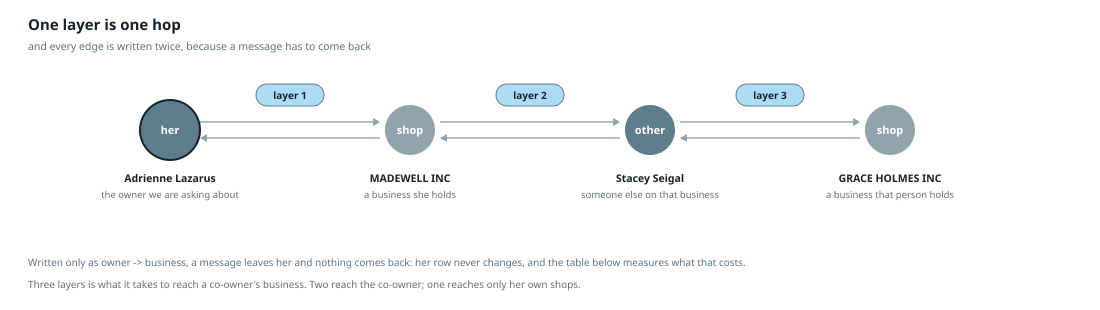

edge_index built as            edges      AUC
----------------------------------------------


both directions              575,034   0.7283


business -> owner only       287,517   0.7202


owner -> business only       287,517   0.6964



the same net, no edges at all         0   0.6964


In [15]:
# The four stops of the figure, out of the graph rather than invented. The owner
# is pinned by her cluster, as everywhere in this notebook -- a name is not a
# key -- and the query derives the rest, asserting what the drawing claims:
# both businesses hold a licence from before 2015, so they are in the snapshot
# the model reads; and the fourth stop is not one of hers, so it really does
# sit three hops away. `ORDER BY` pins which of her co-owner's businesses is
# drawn: Stacey Seigal holds three, and without it the figure changes between runs.
CHAIN = """
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
  WHERE p.clusterId = $cluster
MATCH (o1:Organization {source:'LICENSES'})
  WHERE o1.id = r.employerId
    AND EXISTS { MATCH (o1)-[:ORG_HAS_LICENSE]->(x:LicenseRecord)
                 WHERE toInteger(right(x.startDate,4)) <= 2015 }
MATCH (q:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p2:Person)
  WHERE q.employerId = o1.id AND p2.clusterId <> p.clusterId
MATCH (q2:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p3:Person)
  WHERE p3.clusterId = p2.clusterId AND q2.employerId <> o1.id
MATCH (o2:Organization {source:'LICENSES'})
  WHERE o2.id = q2.employerId
    AND EXISTS { MATCH (o2)-[:ORG_HAS_LICENSE]->(y:LicenseRecord)
                 WHERE toInteger(right(y.startDate,4)) <= 2015 }
    AND NOT EXISTS {
      MATCH (mine:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(pm:Person)
      WHERE pm.clusterId = p.clusterId AND mine.employerId = o2.id }
RETURN DISTINCT r.fullName AS owner, o1.name AS business,
       q.fullName AS co_owner, o2.name AS second
ORDER BY second
LIMIT 1
"""

with driver.session(database=DATABASE) as session:
    chain = dict(session.run(CHAIN, cluster="R3000050").single())

display(SVG(hops_picture([chain["owner"], chain["business"],
                          chain["co_owner"], chain["second"]])))

# What the direction of an edge is worth, measured rather than argued. The graph
# is built with both directions; these are the two halves on their own.
DIRECTIONS = [
    ("both directions", np.concatenate([owns, owns[:, ::-1]])),
    ("business -> owner only", owns[:, ::-1]),
    ("owner -> business only", owns),
]

print(f"{'edge_index built as':26s} {'edges':>9s} {'AUC':>8s}")
print("-" * 46)
for name, array in DIRECTIONS:
    index = torch.tensor(array.T.copy()).to(device)
    print(f"{name:26s} {len(array):>9,} {train_net(0, index):>8.4f}")
print(f"\n{'the same net, no edges at all':26s} {0:>9,} "
      f"{train_net(0, no_edges):>8.4f}")

## What the direction of an edge is worth

`owner -> business only` and `no edges at all` score the same to four decimals,
and that is not a coincidence. `SAGEConv` aggregates **at the node an edge
points to**. Write the edges one way and the owners are never pointed at, so
their rows are exactly what the register gave them: the graph is there, and for
the nodes we are scoring it does not exist.

Reverse them and she receives her businesses — but the businesses now receive
nothing, so her co-owners never reach her. That is one hop, and it is worth most
of the margin.

| `edge_index` written as | what reaches her |
|---|---|
| `owner -> business` | nothing |
| `business -> owner` | her own businesses |
| both | her businesses, her co-owners, and their businesses |

Which is why every edge in this notebook is written twice. It is not tidiness:
with half of them the model is an MLP with extra steps.


## The same shape, on a graph nobody chose

Four models see the owner's twenty-seven columns. One sees the graph.

The `here` column is one draw and sixty epochs, about a minute; the `full run`
column is four draws and four hundred, twenty minutes. They do not agree on the
digits and they agree on the ranking: **the model that reads the edges comes
first**, by 3.2 points here and 5.6 in the full run.

That is the karate club result surviving a change of graph — from 34 members
chosen for a textbook to 69,822 owners nobody curated, and from four columns to
twenty-seven.

What it is **not** yet is a number you could quote. It was measured the way
these things are usually measured, and the next section takes that apart.


## The same question, split another way

The table above was built the way tables are built: put the owners in a random
order, train on seven in ten, score the other three. Nothing unusual about it,
which is the problem.

Look at what a random order does on this graph. A business with two owners took
one licence in 2019 — so **both of them are a 1, and that is one fact written
twice.** A random order drops one of the two into the training half with the
answer attached, and leaves the other in the test set waiting to be guessed.

Nothing is broken and nothing warns you. The model never sees a test owner's
label; it is handed the same input twice, once with the answer.

So, before touching a model: count how many of those pairs a random order
cuts in half.


In [16]:
from scipy import sparse
from scipy.sparse.csgraph import connected_components

# The co-ownership graph: two owners are joined when they hold a business
# together. It is not in the data -- there is no owner-to-owner edge -- so it is
# `P @ P.T`, the two-hop projection of the graph the network trains on.
#
# The business indices in `owns` are offset by the number of people, because the
# nodes are one array: here they have to come back to their position inside the
# business block.
incidence = sparse.csr_matrix(
    (np.ones(len(owns), dtype=np.float32), (owns[:, 0], owns[:, 1] - len(people))),
    shape=(len(people), len(shops)))
together = (incidence[knowable] @ incidence[knowable].T).tocsr()
together.setdiag(0)
together.eliminate_zeros()

holdings = np.asarray(incidence[knowable].sum(1)).ravel()
pairs = sparse.triu(together, k=1).tocoo()
# Both hold exactly one business, so it is the same business, so the same licence
# decides both labels. Not a correlation: an identity.
same_fact = (holdings[pairs.row] == 1) & (holdings[pairs.col] == 1)

components, group = connected_components(together, directed=False)


def by_component(seed, test_share=0.3, valid_share=0.2):
    """Whole groups to one slice. Co-owners are never split.

    Groups go in whole, so the slices are a little uneven: components do not
    divide into exact thirds, and the largest of them holds 13,290 owners. They
    are left uneven rather than forced -- trimming a group to hit a round third
    puts part of it on the other side, which is the thing this function exists
    to prevent.
    """
    rng = np.random.default_rng(seed)
    order = rng.permutation(components)
    size = np.bincount(group, minlength=components)
    where = np.zeros(components, dtype=np.int8)      # 0 train, 1 valid, 2 test
    taken, target = 0, int(len(knowable) * test_share)
    for g in order:
        if taken >= target:
            break
        where[g] = 2
        taken += size[g]
    rest = [g for g in order if where[g] == 0]
    taken, target = 0, int(sum(size[g] for g in rest) * valid_share)
    for g in rest:
        if taken >= target:
            break
        where[g] = 1
        taken += size[g]
    per_owner = where[group]
    return (np.flatnonzero(per_owner == 0), np.flatnonzero(per_owner == 1),
            np.flatnonzero(per_owner == 2))


def cut_pairs(slicer):
    """How many same-fact pairs land one in training and one in test."""
    total = 0
    for seed in range(4):
        train, _, test = slicer(seed)
        in_train = np.zeros(len(knowable), dtype=bool)
        in_test = np.zeros(len(knowable), dtype=bool)
        in_train[train], in_test[test] = True, True
        straddles = ((in_train[pairs.row] & in_test[pairs.col])
                     | (in_test[pairs.row] & in_train[pairs.col]))
        total += int((straddles & same_fact).sum())
    return total // 4


# The one number out of this cell, and the figure below says it: how many pairs
# that are one fact a draw puts on opposite sides of the split.
RANDOM_CUT = cut_pairs(three_slices)
COMPONENT_CUT = cut_pairs(by_component)


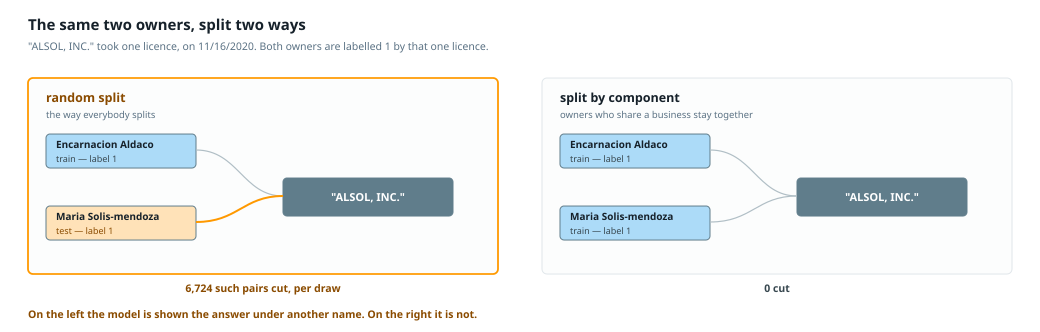

In [17]:
# One business with exactly two owners whose licence falls in the window. Picked
# by the query, with two conditions: the owners must resolve to two *different*
# people and carry two different names. The first business returned without them
# had Dorothy Williams as both president and secretary, which reads as one
# person holding two labels and tells the wrong story.
PAIR = """
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
MATCH (o:Organization {source:'LICENSES'}) WHERE o.id = r.employerId
MATCH (o)-[:ORG_HAS_LICENSE]->(l:LicenseRecord)
WITH o, r, p, max(CASE WHEN toInteger(right(l.startDate,4)) >= 2018
                        AND toInteger(right(l.startDate,4)) <  2021
                       THEN l.startDate END) AS started
WITH o, started, collect({name: r.fullName}) AS owners,
     count(DISTINCT p.clusterId) AS people
WHERE size(owners) = 2 AND people = 2 AND started IS NOT NULL
  AND owners[0].name <> owners[1].name
RETURN o.name AS business, started, owners ORDER BY o.name LIMIT 1
"""

with driver.session(database=DATABASE) as session:
    pair = dict(session.run(PAIR).single())

display(SVG(two_splits(pair, {"random": RANDOM_CUT,
                              "component": COMPONENT_CUT})))


In [18]:
# The same five models, the same seeds, the same columns. One thing changes.
MEASURED_HONEST = {"logistic regression": 0.6917, "random forest": 0.6710,
                   "gradient boosting": 0.7101, "MLP, no edges": 0.7211,
                   "GNN": 0.7227}

print(f"{'model':22s} {'edges':>6s} {'random':>8s} {'by component':>14s} "
      f"{'full run':>10s}")
print("-" * 66)
honest = run_with(0, by_component)
for name, edges, _ in ROWS:
    print(f"{name:22s} {edges:>6s} {RANDOM[name]:>8.4f} {honest[name]:>14.4f} "
          f"{MEASURED_HONEST[name]:>10.4f}")


model                   edges   random   by component   full run
------------------------------------------------------------------


logistic regression        no   0.6879         0.6779     0.6917
random forest              no   0.6782         0.6612     0.6710
gradient boosting          no   0.7050         0.6918     0.7101
MLP, no edges              no   0.6964         0.6837     0.7211
GNN                       YES   0.7285         0.7071     0.7227


## What the random order was worth

Same owners, same columns, same five models, same seed. One thing changed:
whether two people who share a business may sit on opposite sides of the split.

The GNN's lead over the best model that ignores the graph goes from **5.6 points
to 0.2** in the full run, and 0.2 is nothing — over the four seeds that run
used, the seed-to-seed spread was itself 0.008. The column measured here is one
seed and sixty epochs, so it shows the compression and not its full size.

**And the models that never look at an edge barely move.** They could not reach
the answer through a co-owner, so there was nothing to take away from them. That
asymmetry is the finding: the honest split costs the models that traverse the
graph and leaves the others where they were.

Read the two tables together and the lesson is not about graph neural networks
at all. It is that a number this size is decided before a model is fitted, by a
choice nobody writes down: **who is allowed to be in the test set.**


## Handing it to the agent

The agent of module 5 answers questions about Chicago contracts by choosing
among eight tools. None of them can answer *"is this owner about to go quiet?"*,
because that is not a fact in the graph — it is the output of something we
trained.

So it becomes a ninth tool. The arrangement is module 6's, which added `recall`
the same way: the agent is told a tool exists, and left to decide whether to
reach for it.

Two things make this worth doing rather than just calling the model ourselves.
The agent has to **choose** it over the tools that read facts, which is a test of
whether one sentence can describe a model. And the tool has to hand back
something honest: a probability, what it was computed from, and the window it
applies to — because an agent given a bare number will put it in a sentence as
if it were a fact.


In [19]:
# The engine is loaded, not trained here. Four hundred epochs on the honest
# split is five minutes, and a lesson that trains the same thing twice spends a
# twentieth of the session recomputing a number already on the screen.
#
# `train_gnn.py` saved nothing until today -- it trained, measured, printed and
# dropped the model -- so the register has numbers whose models no longer exist.
# This one is on disk with what it scored, and the cell checks that claim rather
# than printing it.
import json
from pathlib import Path

CARD = json.loads(Path("../../serving/gnn/owner_filing.json").read_text())
engine = Net(features.shape[1]).to(device)
# `weights_only=True` because this file is a state dict and nothing else.
# Without it torch warns, at length, in the middle of the lesson -- and the
# warning is right: the default unpickles whatever is in the file.
engine.load_state_dict(torch.load("../../serving/gnn/owner_filing.pt",
                                  map_location=device, weights_only=True))
engine.eval()
with torch.no_grad():
    chances = torch.sigmoid(engine(all_features, both_ways)).cpu().numpy()

train, valid, test = by_component(CARD["seed"])
held_out = roc_auc_score(label[test], chances[knowable[test]])
# The card's number, re-measured here, and the cell stops if the two disagree.
# An assertion and not a print: the only interesting outcome is the one where
# the features this notebook built are not the ones the engine was trained on,
# and that outcome has to stop the lesson rather than scroll past in a line.
assert abs(held_out - CARD["test"]) < 0.002, (
    "the loaded engine does not reproduce its own card: the features this "
    "notebook built are not the ones it was trained on")

# Every word of the name, in any position, rather than the whole string as one
# substring. The register writes `Monica L Haslip` and an agent passes
# `Monica Haslip`, so a `CONTAINS` on the whole thing finds nobody -- which is
# what this tool did until the fallback below printed its empty answer out loud.
BY_NAME = """
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
  WHERE ALL(word IN split(toLower($name), ' ')
            WHERE toLower(r.fullName) CONTAINS word)
MATCH (o:Organization {source:'LICENSES'}) WHERE o.id = r.employerId
RETURN p.clusterId AS person, collect(DISTINCT r.fullName)[0] AS name,
       count(DISTINCT o) AS businesses
ORDER BY businesses DESC LIMIT 4
"""


def chance_for(name):
    """Every owner whose recorded name contains `name`, with their score."""
    with driver.session(database=DATABASE) as session:
        found = [dict(r) for r in session.run(BY_NAME, name=name)]
    out = []
    for row in found:
        node = at.get(row["person"])
        if node is None:
            continue
        out.append({"person": row["person"], "name": row["name"],
                    "businesses": row["businesses"],
                    "chance": float(chances[node])})
    return out


## Asking about one owner, from scratch

The scores above were read off one pass over the whole graph. That is fine for a
table and wrong for a tool: it can only answer about the 193,848 owners who were
in the graph when the network was trained.

`SAGEConv` does not need them to be. It learned a function of a neighbourhood,
so given **one owner's** neighbourhood — their businesses, the people on
those, those people's businesses — it will score them without ever having seen
them.

Which means the tool has to build that neighbourhood itself, from the graph, and
encode it into the same 52 columns. Two code paths now produce the same
features, and two code paths that are supposed to agree are the single most
reliable way to be wrong quietly. So the cell asserts it: three layers reach
three hops and no further, so a score computed from one owner's own
neighbourhood has to be the number the whole-graph pass gave them — not close to
it, the same.


In [20]:
AROUND = """
// Three hops from one owner, in the order the network propagates them: one hop
// to their businesses, two to the people on those, three to those people's.
//
// The hops are separate `WITH` stages because an aggregate cannot be used in the
// `WHERE` that filters it -- the first version put `collect()` inside a `WHERE`
// and Neo4j refused, which is the right refusal.
//
// The third hop starts again from the *people*, and that is the whole fix found
// on 26/11/2026. It used to re-collect `employerId` off the records already
// matched -- and those were filtered to the owner's own businesses, so hop three
// handed back the first one and the co-owners' businesses were never fetched.
// Nothing failed: the subgraph was simply one hop short, and it showed up only
// as the check below disagreeing with the whole-graph pass in the third decimal
// for exactly the two owners whose co-owners hold something else.
MATCH (r0:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p0:Person)
  WHERE p0.clusterId = $person
WITH collect(DISTINCT r0.employerId) AS mine
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
  WHERE r.employerId IN mine
WITH mine, collect(DISTINCT p.clusterId) AS people
MATCH (r2:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p2:Person)
  WHERE p2.clusterId IN people
WITH mine, people, collect(DISTINCT r2.employerId) AS theirs
RETURN people, [x IN mine + theirs WHERE x IS NOT NULL] AS shops
"""


def subgraph_of(person):
    """The node ids within three hops, and the edges among them.

    Returned as positions in a *new* array, numbered from zero: this is the
    shape a tool would build for an owner the training graph never held, and
    numbering it off the big array would hide that.
    """
    with driver.session(database=DATABASE) as session:
        found = session.run(AROUND, person=person).single()
    local_people = sorted(set(found["people"]) | {person})
    local_shops = sorted(set(found["shops"]))
    place = {k: i for i, k in enumerate(local_people)}
    place.update({k: len(local_people) + i for i, k in enumerate(local_shops)})
    here = owners[owners["person"].isin(local_people)
                  & owners["business"].isin(local_shops)]
    local_edges = np.array(sorted({(place[a], place[b])
                                   for a, b in zip(here["person"],
                                                   here["business"])}),
                           dtype=np.int64)
    return local_people, local_shops, place, local_edges


def encode_subgraph(local_people, local_shops, place):
    """The 52 columns for a subgraph, taken from the rows the bulk build made.

    Taken and not recomputed, on purpose: a second encoder written for this path
    is a second chance to disagree with the first, and the module's whole point
    is that two numbers which should match are worth checking rather than
    trusting. What makes this inductive is not where the columns come from -- it
    is that the forward pass sees only the subgraph.
    """
    rows = np.zeros((len(local_people) + len(local_shops), features.shape[1]),
                    dtype=np.float32)
    for key, slot in place.items():
        rows[slot] = features[at[key]]
    return rows


def ask_about(person, threshold=0.5):
    """Score one owner from their own neighbourhood alone."""
    local_people, local_shops, place, local_edges = subgraph_of(person)
    rows = encode_subgraph(local_people, local_shops, place)
    both = np.concatenate([local_edges, local_edges[:, ::-1]]).T.copy()
    with torch.no_grad():
        engine.eval()
        score = torch.sigmoid(engine(
            torch.tensor(rows).to(device),
            torch.tensor(both).to(device)))[place[person]].item()
    return {"chance": score, "yes": score >= threshold,
            "people_seen": len(local_people), "shops_seen": len(local_shops),
            "edges_seen": len(local_edges)}


# The check, and it is the whole claim of this section: three layers reach three
# hops and no further, so an owner's score cannot depend on anything outside
# their own three-hop neighbourhood. That number out of a graph of a dozen nodes
# has to
# be the number the whole-graph pass gave them -- not close to it, the same.
#
# An assertion and not a table, for the reason the engine's card is one: the
# only interesting outcome is the one that stops the lesson. A subgraph built
# one hop short still trains, still answers and still looks right; what it does
# is disagree here, in the third decimal, and only for the owners whose
# co-owners hold something else. That is how the query above was found to be
# wrong, on 26/11/2026.
for _person in (str(k) for k in owners["person"].drop_duplicates().iloc[:4]):
    assert abs(ask_about(_person)["chance"] - float(chances[at[_person]])) < 1e-5, (
        f"{_person} scores differently from their own neighbourhood than from the "
        f"whole graph: the subgraph the tool builds is not the one the network "
        f"was trained on")

CHECK = """
MATCH (r:PersonRecord {source:'OWNERS'})-[:RECORD_RESOLVED_TO]->(p:Person)
  WHERE p.clusterId = $person
MATCH (o:Organization {source:'LICENSES'}) WHERE o.id = r.employerId
MATCH (o)-[:ORG_HAS_LICENSE]->(l:LicenseRecord)
WITH o, l, [yy IN [toInteger(right(l.startDate,4))]
            WHERE yy >= 2018 AND yy < 2021] AS inside
RETURN count(CASE WHEN size(inside) > 0 THEN 1 END) AS in_window,
       collect(DISTINCT CASE WHEN size(inside) > 0 THEN l.startDate END)[0..3]
         AS dates
"""


In [21]:
# The engine, used. This is the whole interface: a name goes in, an answer comes
# out, and between the two there is one query and one forward pass. Everything
# after this cell is about who does the calling.
#
# Giovanni Delisi is in the held-out third under the component split, so the
# engine was never shown his answer, and his neighbourhood is three nodes: him,
# his co-owner, and the trattoria. Three out of 390,464, and they are enough --
# the assertion above is what says so. The graph's answer is printed beside the
# model's, because a demonstration that does not say what actually happened is
# not a demonstration.
with driver.session(database=DATABASE) as session:
    truth = dict(session.run(CHECK, person="L11677").single())

print(f"the graph: {truth['in_window']} licences started 2018-2021 "
      f"({', '.join(d for d in truth['dates'] if d)})")
ask_about("L11677")   # Giovanni Delisi, president of TRATTORIA GIANNI, INC.


the graph: 6 licences started 2018-2021 (04/16/2019)


{'chance': 0.8710559606552124,
 'yes': True,
 'people_seen': 2,
 'shops_seen': 1,
 'edges_seen': 2}

In [22]:
# A. Elizabeth Ortner is the owner the timeline figure left with a question
# mark, and this is where the question gets answered. Monica Haslip is beside
# her as the other side of the coin: the histories are the same shape up to 2015
# and the model separates them.
#
# Both are in the held-out third, so neither was in the loss. Both names are
# public record.
for who in ("A. Elizabeth Ortner", "Monica L Haslip"):
    for row in chance_for(who):
        local = ask_about(row["person"])
        with driver.session(database=DATABASE) as session:
            truth = dict(session.run(CHECK, person=row["person"]).single())
        got_it = local["yes"] == (truth["in_window"] > 0)
        print(f"{row['name']}  —  {row['businesses']} business"
              f"{'es' if row['businesses'] > 1 else ''}")
        print(f"   the model, from {local['people_seen']} owners and "
              f"{local['shops_seen']} businesses around her: "
              f"{'yes' if local['yes'] else 'no'} ({local['chance']:.0%})")
        print(f"   the graph: {truth['in_window']} licence"
              f"{'s' if truth['in_window'] != 1 else ''} started 2018-2021"
              + (f" ({', '.join(d for d in truth['dates'] if d)})"
                 if truth["dates"] and truth["dates"][0] else ""))
        print(f"   -> {'right' if got_it else 'WRONG'}\n")


A. Elizabeth Ortner  —  1 business
   the model, from 1 owners and 1 businesses around her: no (44%)
   the graph: 0 licences started 2018-2021
   -> right



Monica L Haslip  —  2 businesses
   the model, from 3 owners and 6 businesses around her: yes (99%)
   the graph: 6 licences started 2018-2021 (01/16/2019, 09/19/2018, 05/07/2019)
   -> right



In [23]:
import sys

sys.path.insert(0, "../05-graphrag")
from pipelines.react import TOOLS, agent

# Module 5's own closing tool, taken rather than retyped. Its graph nudges the
# model once to finish by calling `answer`, so an agent without that tool spends
# its last step explaining that it cannot find it -- which is what the first run
# of this cell did. `purchase_orders` is optional there, and with an empty list
# `render_answer` returns the summary alone, which is what an owner question
# needs.
ANSWER = next(t for t in TOOLS if t["function"]["name"] == "answer")

# The tool, in the shape the agent's API expects. The description is the whole
# interface: it is the only thing the model reads before deciding to call this
# rather than a tool that reads a fact.
FILING = {"type": "function", "function": {
    "name": "chance_of_filing",
    "description": ("Whether a business owner is likely to file another licence "
                    "in the three years after 2015, yes or no, with the "
                    "probability behind it. Pass the owner's name. This is a "
                    "prediction from a graph network, not something the records "
                    "state -- use it when asked what is likely, never to state "
                    "what happened."),
    "parameters": {"type": "object", "required": ["owner"], "properties": {
        "owner": {"type": "string"}}}}}

ROUTING = ("A question about what an owner is *likely* to do: "
           "chance_of_filing, with the name.")


def filing_handler(args):
    """What the agent gets back. Prose, because `run_tool` is typed to `str`.

    It returns the number with the three things that bound it: how many owners
    matched, what the window is, and how good the engine is. An agent handed a
    bare 0.78 writes it into a sentence as a fact -- module 5 measured that in
    its own way with `render_answer`, and the fix there was the same: do not make
    the model responsible for the caveat.
    """
    name = str(args.get("owner") or "").strip()
    if not name:
        return "chance_of_filing needs an owner's name."
    found = chance_for(name)
    if not found:
        return f"no owner on record whose name contains {name!r}."
    lines = []
    for row in found:
        # Scored from her own neighbourhood, not read off the whole-graph pass:
        # the same call would work for an owner added to the graph tomorrow.
        local = ask_about(row["person"])
        lines.append(
            f"{row['name']}: {'yes' if local['yes'] else 'no'} "
            f"({local['chance']:.0%}, threshold 50%) — scored from "
            f"{local['people_seen']} owners and {local['shops_seen']} businesses "
            f"around her")
    return ("\n".join(lines)
            + f"\n\nModelled, not recorded: a graph network scoring AUC "
              f"{held_out:.2f} on owners it never saw. The window is 2018-2021, "
              f"seen from 2015. It is not a statement about any person and "
              f"decides nothing about them.")

In [24]:
# The tool, called by hand. No agent, no model: this is the string the agent
# will be handed when it decides to call `chance_of_filing`, and it is worth
# reading before an agent is in the room.
print(filing_handler({"owner": "Sarkisian"}))


A Alex Sarkisian: yes (70%, threshold 50%) — scored from 6 owners and 34 businesses around her

Modelled, not recorded: a graph network scoring AUC 0.71 on owners it never saw. The window is 2018-2021, seen from 2015. It is not a statement about any person and decides nothing about them.


In [25]:
from neo4j import GraphDatabase as _GD

# The agent's own session. Module 5's `agent` takes one and runs its tools
# through it; here it gets the tool list and the prompt that go with this one
# tool, because passing a short list with module 5's full prose would order the
# model to call seven tools it does not have.
SYSTEM = """You answer questions about business owners in the City of Chicago.

Two tools. """ + ROUTING + """
Then finish by calling `answer` with a short summary and an empty
`purchase_orders` — this question is not about contracts.

Repeat the tool's caveat in your own words: the number is modelled, not
recorded, so say so in the same breath you say the number, and never present it
as something the records state."""

QUESTION = "Is Monica Haslip likely to file another licence?"

# The served model is not always up, and a cell that dies on a connection error
# takes the room's attention with it. If the endpoint does not answer, the tool
# still does: it is a Cypher and a forward pass, and neither needs a model. What
# is lost is the agent *choosing* to call it, and the cell says so rather than
# printing a transcript recorded somewhere else.
with _GD.driver("bolt://localhost:7687",
                auth=("neo4j", os.environ.get("NEO4J_PASSWORD", "password"))
                ).session(database=DATABASE) as session:
    try:
        turn = agent(session, QUESTION, tools=[FILING, ANSWER], system=SYSTEM,
                     extra_tools={"chance_of_filing": filing_handler})
        print("\ntools the agent chose:",
              [step.get("tool") for step in turn["trace"] if step.get("tool")])
    except Exception as failure:
        print(f"the served model did not answer: {type(failure).__name__}")
        print("so here is the tool on its own, which needs no model:\n")
        print(filing_handler({"owner": "Monica Haslip"}))


the served model did not answer: NotFoundError
so here is the tool on its own, which needs no model:



Monica L Haslip: yes (99%, threshold 50%) — scored from 3 owners and 6 businesses around her

Modelled, not recorded: a graph network scoring AUC 0.71 on owners it never saw. The window is 2018-2021, seen from 2015. It is not a statement about any person and decides nothing about them.


## What the module leaves you with

| the decision | what it bought | what it cost |
|---|---|---|
| use the graph at all | +5.6 points over the best model that ignores it | two queries |
| write every edge in both directions | the whole margin — one direction scores exactly what no edges score | nothing |
| split the owners at random | +5.4 of those +5.6 points | a leak nothing warns you about |
| keep co-owners together | the honest number | 6,724 pairs stop being free |

Four things that travel to a graph that is not this one:

**A graph is not a table, and the only way to make it one is to combine the
neighbours.** That combining is an average — `GCNConv` rebuilt by hand to seven
decimal places — and what a network adds is the weights on it, not the
combining.

**Direction decides whether the graph exists at all.** Written one way, the
nodes you are scoring are never pointed at, and the model is an MLP with extra
steps. The two halves of the same edge list score 0.73 and 0.70.

**The split is a modelling decision, and the biggest one here.** Who is allowed
in the test set moved this table by five points — more than the choice of model,
more than the architecture, more than the features.

**Two rows that are the same fact are one row.** When a business with two
owners files once, both owners are labelled 1 by that single licence — one fact
written twice. A random draw cuts 6,724 such pairs, handing the model one half
with the answer attached and asking it to guess the other. No model can be asked
to tell them apart, and any score that counts both is counting one thing twice.

The last one is the exercise to take away: on a graph of your own, find the rows
that are the same fact under two names. Nobody will have told you they are
there, and no model will complain.
